# Assignment 10: Iris Dataset Classification using Random Forest Classifier
**Done Date:** 29-10-2026  
**Aim:** Implement a Random Forest Classifier using Scikit-Learn on the Iris dataset (`iris_dataset_RF.csv`) and evaluate model performance using Accuracy, Confusion Matrix, and Classification Report metrics (Precision, Recall, F1-Score).  
**Tools / Libraries:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn` (`sklearn.ensemble.RandomForestClassifier`)  
**Programming Platform / Language:** Jupyter Notebook, Python

## Theory & Task Overview

### Random Forest Classifier
Random Forest is an ensemble learning method that constructs a multitude of Decision Trees during training. 
* **Bagging (Bootstrap Aggregating):** Each tree is trained on a random bootstrap sample of the dataset.
* **Feature Randomness:** At each node split in a tree, a random subset of features is evaluated to find the best split.
* **Majority Voting:** For classification tasks, the output is determined by majority voting across all decision trees, making Random Forest highly accurate and resistant to overfitting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load the Iris dataset for Random Forest
df = pd.read_csv('iris_dataset_RF.csv')

# 2. Separate features (X) and target/species (y)
X = df.iloc[:, :-1]  # Features: SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm
y = df.iloc[:, -1]   # Target: Species

# 3. Split dataset into Training (80%) and Testing (20%) sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Dataset loaded and split successfully!")
print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

Dataset loaded and split successfully!
Training samples: 120 | Testing samples: 30


---
## Model Implementation: Random Forest Classifier

In [2]:
# 1. Initialize Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Fit model on training set
rf_model.fit(X_train, y_train)

# 3. Predictions on testing set
y_pred = rf_model.predict(X_test)

# 4. Compute Accuracy
accuracy = accuracy_score(y_test, y_pred)

# 5. Compute Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Display Results
print("=" * 55)
print("        RANDOM FOREST CLASSIFIER EVALUATION        ")
print("=" * 55)
print(f"Accuracy Score : {accuracy * 100:.2f}%\n")

print("Confusion Matrix:")
print(cm)
print("\n" + "=" * 55)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

        RANDOM FOREST CLASSIFIER EVALUATION        
Accuracy Score : 90.00%

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30



C:\Users\ramje\AppData\Local\Temp\ipykernel_18092\3310125562.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances, y=feature_names, palette='viridis', ax=axes[1])


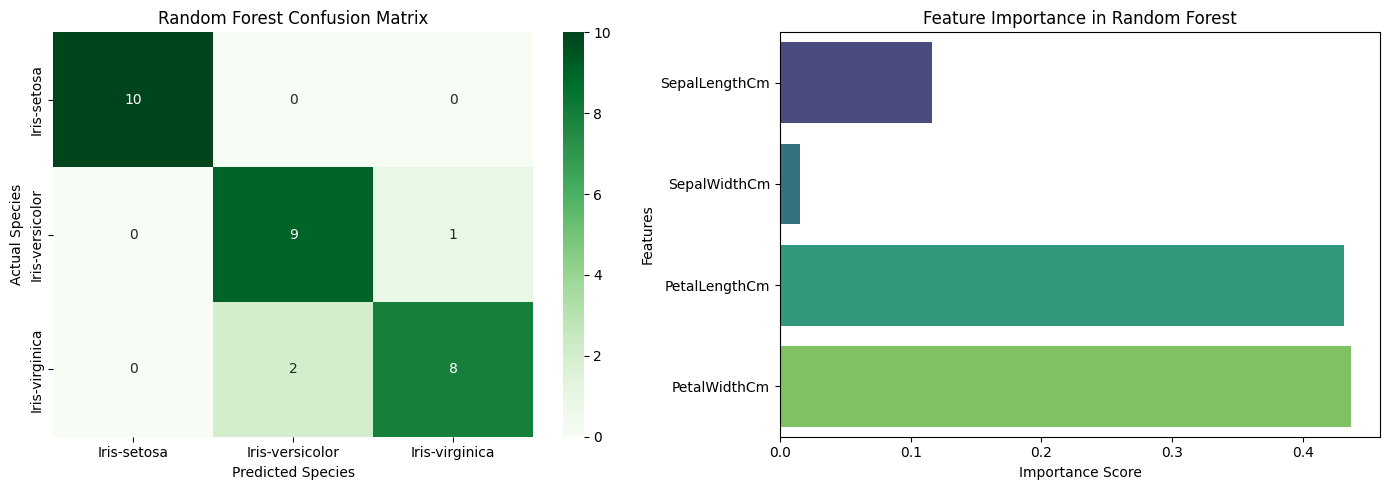

In [3]:
# Create side-by-side plots: Confusion Matrix Heatmap and Feature Importance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Heatmap
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Greens', 
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_,
    ax=axes[0]
)
axes[0].set_title('Random Forest Confusion Matrix')
axes[0].set_xlabel('Predicted Species')
axes[0].set_ylabel('Actual Species')

# 2. Feature Importance Plot
importances = rf_model.feature_importances_
feature_names = X.columns

sns.barplot(x=importances, y=feature_names, palette='viridis', ax=axes[1])
axes[1].set_title('Feature Importance in Random Forest')
axes[1].set_xlabel('Importance Score')
axes[1].set_ylabel('Features')

plt.tight_layout()
plt.show()